# PredictGuard AI — Phase 5: Clustering
**Covers Practical 06 — K-Means (k=3, k=4), Hierarchical Clustering, squared error, optimal k**

Dataset: AI4I 2020 Predictive Maintenance. Clustering is **unsupervised**: the failure label is *not* used to form clusters. It is used only afterwards to interpret them and to assign risk tiers (Low / Medium / High) for the dashboard.

## Step 1 — Load the AI4I dataset

In [ ]:
!wget -q "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip" -O ai4i.zip
!unzip -o -q ai4i.zip -d /content/ai4i_data
!ls /content/ai4i_data

ai4i2020.csv


In [ ]:
import pandas as pd, numpy as np
df = pd.read_csv("/content/ai4i_data/ai4i2020.csv")
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 2 — Feature selection and scaling
Only the five numeric sensor features are used (distance-based clustering works on numeric data; the one-hot `Type` column would add a binary dimension that distorts distances). Scaling is essential, otherwise rpm (~1500) would dominate temperature (~300) and torque (~40).

In [ ]:
from sklearn.preprocessing import StandardScaler

numeric_features = ["Air temperature [K]", "Process temperature [K]",
                    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
X = df[numeric_features].values
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
y_fail = df["Machine failure"].values   # used ONLY for interpretation later

print("Scaled shape:", Xs.shape)
print("Total sum of squares (SSE with k=1):", round(((Xs - Xs.mean(axis=0))**2).sum(), 2))

Scaled shape: (10000, 5)
Total sum of squares (SSE with k=1): 50000.0


## Step 3 — K-Means with k = 3 and k = 4
Squared error (SSE, a.k.a. inertia) = sum of squared distances from every point to its cluster centroid. Lower is tighter, but SSE always falls as k grows, so it can't pick k by itself.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

def sse(Xdata, labels):
    total = 0.0
    for c in np.unique(labels):
        pts = Xdata[labels == c]
        total += ((pts - pts.mean(axis=0))**2).sum()
    return total

kmeans_models = {}
for k in [3, 4]:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    kmeans_models[k] = km
    sil = silhouette_score(Xs, km.labels_, sample_size=3000, random_state=42)
    print(f"K-Means k={k}: SSE={km.inertia_:.2f} | silhouette={sil:.4f} | "
          f"Davies-Bouldin={davies_bouldin_score(Xs, km.labels_):.4f} | sizes={np.bincount(km.labels_).tolist()}")

K-Means k=3: SSE=28305.69 | silhouette=0.2590 | Davies-Bouldin=1.2437 | sizes=[3930, 4017, 2053]
K-Means k=4: SSE=24870.55 | silhouette=0.2381 | Davies-Bouldin=1.2859 | sizes=[3535, 2384, 2368, 1713]


## Step 4 — Finding the optimal k (K-Means)
Two standard criteria: the **elbow** in the SSE curve and the **silhouette score** (higher = better-separated clusters).

In [ ]:
import matplotlib.pyplot as plt

K_RANGE = range(2, 11)
inertias, sils, dbs = {1: ((Xs - Xs.mean(axis=0))**2).sum()}, {}, {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertias[k] = km.inertia_
    sils[k] = silhouette_score(Xs, km.labels_, sample_size=3000, random_state=42)
    dbs[k] = davies_bouldin_score(Xs, km.labels_)

summary = pd.DataFrame({"SSE": inertias, "Silhouette": sils, "DaviesBouldin": dbs})
print(summary.round(4))

# Elbow: point of maximum distance from the line joining first and last SSE values
ks = np.array(sorted(inertias)); vals = np.array([inertias[k] for k in ks])
p1, p2 = np.array([ks[0], vals[0]]), np.array([ks[-1], vals[-1]])
d = [abs(np.cross(p2-p1, p1-np.array([k, v]))) / np.linalg.norm(p2-p1) for k, v in zip(ks, vals)]
elbow_k = int(ks[int(np.argmax(d))])
best_k_sil = max(sils, key=sils.get)
print(f"\nElbow suggests k = {elbow_k}")
print(f"Best silhouette at k = {best_k_sil} (score {sils[best_k_sil]:.4f})")

           SSE  Silhouette  DaviesBouldin
1   50000.0000         NaN            NaN
2   36654.1913      0.2582         1.5163
3   28305.6936      0.2590         1.2437
4   24870.5514      0.2381         1.2859
5   21946.7165      0.2243         1.3734
6   19848.9773      0.2202         1.3332
7   17896.0251      0.2280         1.2229
8   16590.9678      0.2183         1.2348
9   15481.9421      0.2147         1.2161
10  14507.2082      0.2184         1.1652

Elbow suggests k = 3
Best silhouette at k = 3 (score 0.2590)


/tmp/ipykernel_940/4217862963.py:17: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  d = [abs(np.cross(p2-p1, p1-np.array([k, v]))) / np.linalg.norm(p2-p1) for k, v in zip(ks, vals)]


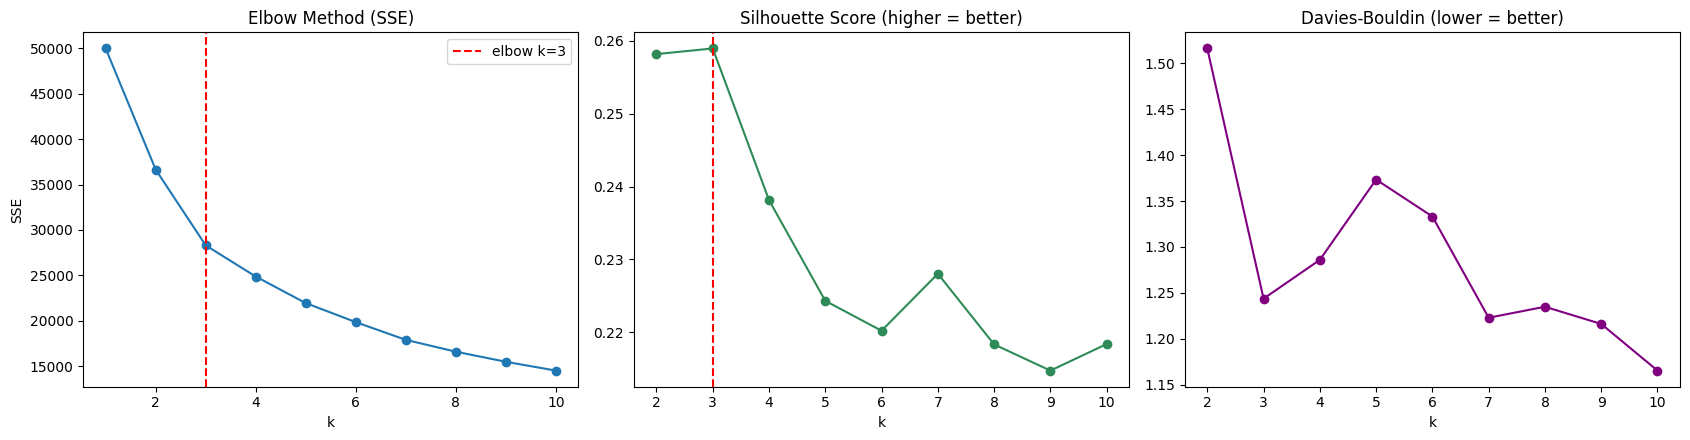

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(ks, vals, "o-"); axes[0].axvline(elbow_k, ls="--", c="r", label=f"elbow k={elbow_k}")
axes[0].set_title("Elbow Method (SSE)"); axes[0].set_xlabel("k"); axes[0].set_ylabel("SSE"); axes[0].legend()

axes[1].plot(list(sils), list(sils.values()), "o-", c="seagreen")
axes[1].axvline(best_k_sil, ls="--", c="r"); axes[1].set_title("Silhouette Score (higher = better)"); axes[1].set_xlabel("k")

axes[2].plot(list(dbs), list(dbs.values()), "o-", c="purple")
axes[2].set_title("Davies-Bouldin (lower = better)"); axes[2].set_xlabel("k")
plt.tight_layout(); plt.savefig("/content/kmeans_k_selection.png", dpi=120); plt.show()

## Step 5 — Hierarchical Clustering (Ward linkage)
Practical 06 asks for squared errors across **all possible cluster counts**. For Ward linkage this is computable exactly and cheaply: each merge increases total SSE by `d²/2` (where `d` is the merge height scipy reports), so the SSE for every k from 1 to N comes from a cumulative sum of the merge heights — no need to cut the tree N times.

In [ ]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

Z = linkage(Xs, method="ward")          # ~400 MB for 10,000 points; fine on Colab
n = Xs.shape[0]

delta_sse = Z[:, 2]**2 / 2              # SSE increase caused by each merge
cum = np.concatenate([[0.0], np.cumsum(delta_sse)])
k_all = n - np.arange(n)                # k = n, n-1, ..., 1
sse_all = cum                           # SSE when there are k_all clusters

hier_sse = pd.Series(sse_all, index=k_all).sort_index()
print("Hierarchical SSE for every possible k (1 .. N):", len(hier_sse), "values")
print("k=1 :", round(hier_sse[1], 2), "(should equal total sum of squares)")
for k in [2, 3, 4, 5, 10]:
    print(f"k={k:<3}: {hier_sse[k]:.2f}")

# Sanity check against directly cutting the tree
for k in [3, 4]:
    lab = fcluster(Z, k, criterion="maxclust")
    print(f"k={k}: direct SSE = {sse(Xs, lab):.2f} vs merge-height SSE = {hier_sse[k]:.2f}")

Hierarchical SSE for every possible k (1 .. N): 10000 values
k=1 : 50000.0 (should equal total sum of squares)
k=2  : 39648.19
k=3  : 33657.45
k=4  : 28988.81
k=5  : 25895.90
k=10 : 17581.20
k=3: direct SSE = 33657.45 vs merge-height SSE = 33657.45
k=4: direct SSE = 28988.81 vs merge-height SSE = 28988.81


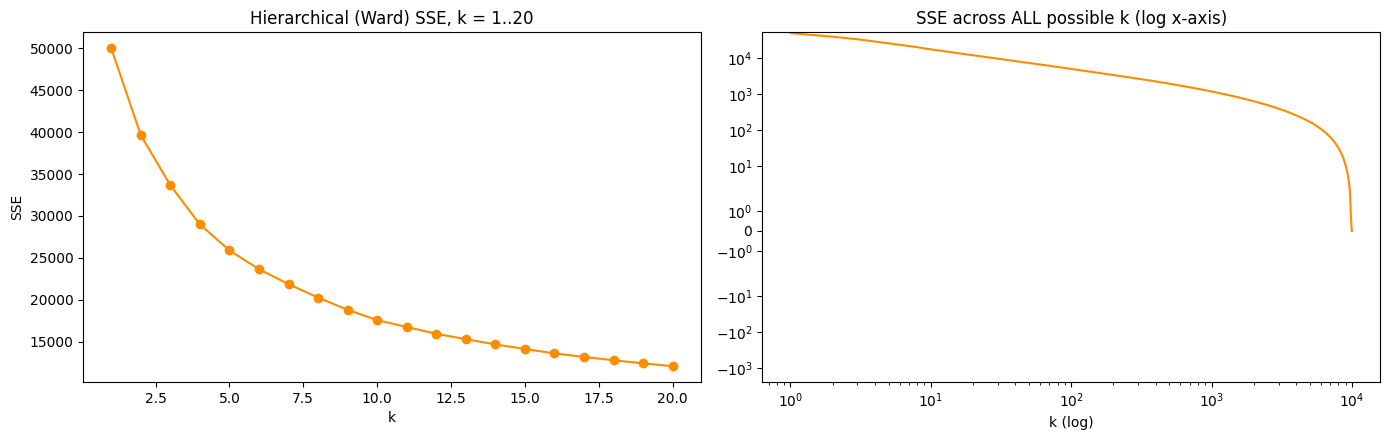

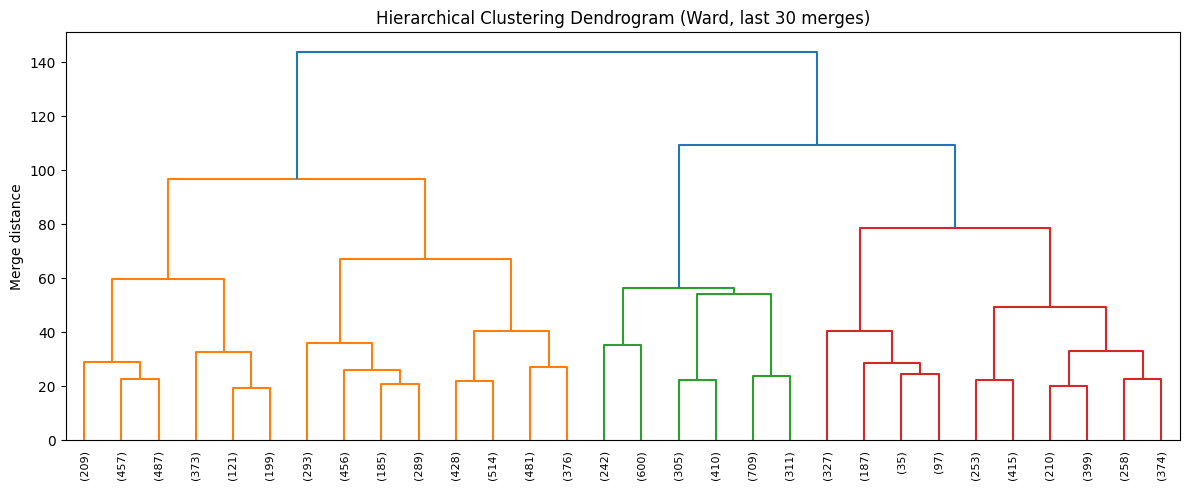

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
small = hier_sse.loc[1:20]
axes[0].plot(small.index, small.values, "o-", c="darkorange")
axes[0].set_title("Hierarchical (Ward) SSE, k = 1..20"); axes[0].set_xlabel("k"); axes[0].set_ylabel("SSE")

axes[1].plot(hier_sse.index, hier_sse.values, c="darkorange")
axes[1].set_xscale("log"); axes[1].set_yscale("symlog")
axes[1].set_title("SSE across ALL possible k (log x-axis)"); axes[1].set_xlabel("k (log)")
plt.tight_layout(); plt.savefig("/content/hierarchical_sse_all_k.png", dpi=120); plt.show()

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8)
plt.title("Hierarchical Clustering Dendrogram (Ward, last 30 merges)")
plt.ylabel("Merge distance"); plt.tight_layout()
plt.savefig("/content/dendrogram.png", dpi=120); plt.show()

## Step 6 — Comparing K-Means vs Hierarchical
For each k: SSE, silhouette score and how much the two methods agree (Adjusted Rand Index, 1.0 = identical clusterings).

In [ ]:
from sklearn.metrics import adjusted_rand_score

K_FINAL = best_k_sil       # change this if you prefer the elbow value
rows = []
for k in sorted(set([3, 4, K_FINAL])):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    hl = fcluster(Z, k, criterion="maxclust")
    rows.append({
        "k": k,
        "KMeans SSE": km.inertia_,
        "Hier SSE": sse(Xs, hl),
        "KMeans silhouette": silhouette_score(Xs, km.labels_, sample_size=3000, random_state=42),
        "Hier silhouette": silhouette_score(Xs, hl, sample_size=3000, random_state=42),
        "Agreement (ARI)": adjusted_rand_score(km.labels_, hl),
    })
compare_df = pd.DataFrame(rows).set_index("k")
print(compare_df.round(4))
compare_df.to_csv("/content/clustering_comparison.csv")

   KMeans SSE    Hier SSE  KMeans silhouette  Hier silhouette  Agreement (ARI)
k                                                                             
3  28305.6936  33657.4463             0.2590           0.1616           0.3460
4  24870.5514  28988.8136             0.2381           0.1549           0.2806


Variance explained by 2 PCs: [0.382 0.368] -> 0.75


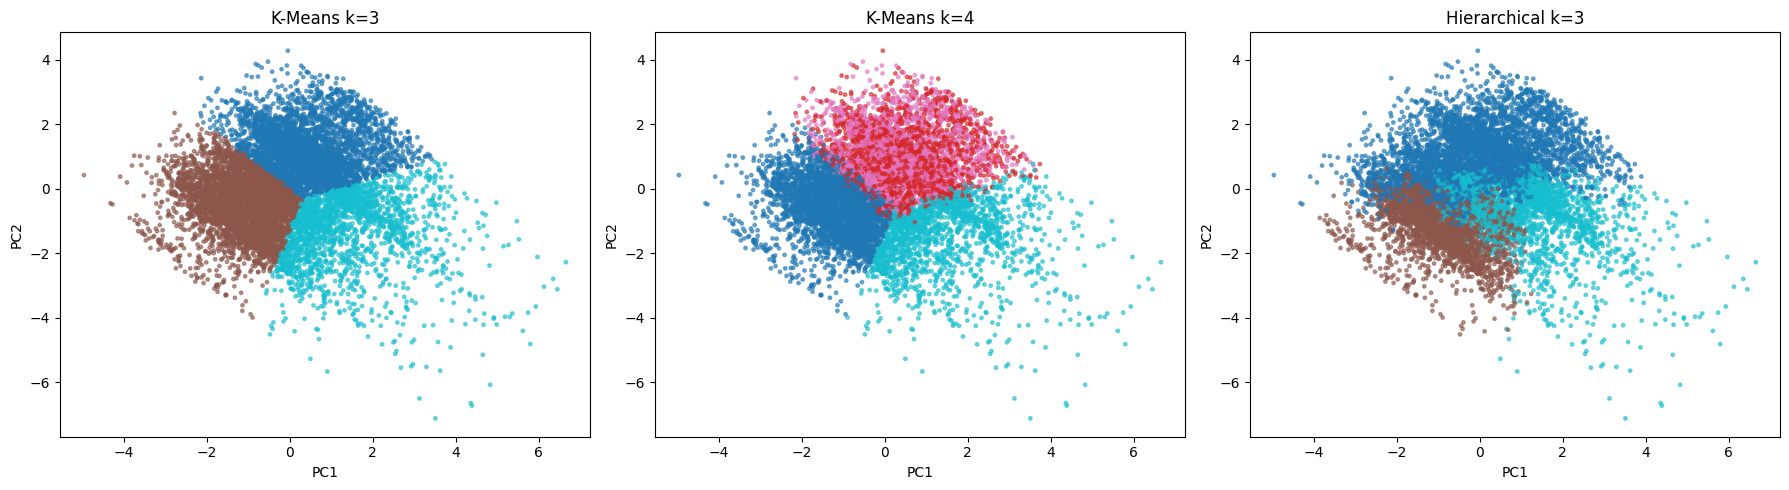

In [ ]:
# Visualise clusters in 2D with PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
Xp = pca.fit_transform(Xs)
print("Variance explained by 2 PCs:", pca.explained_variance_ratio_.round(3), "->", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, lab) in zip(axes, [
        ("K-Means k=3", kmeans_models[3].labels_),
        ("K-Means k=4", kmeans_models[4].labels_),
        (f"Hierarchical k={K_FINAL}", fcluster(Z, K_FINAL, criterion='maxclust') - 1)]):
    sc = ax.scatter(Xp[:, 0], Xp[:, 1], c=lab, cmap="tab10", s=6, alpha=0.6)
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.savefig("/content/cluster_scatter_pca.png", dpi=120); plt.show()

## Step 7 — Profiling the clusters and assigning risk tiers
Now (and only now) the failure label is used: for each final K-Means cluster we look at its average sensor values and its failure rate. Clusters are ranked by failure rate and labelled Low / Medium / High risk. This feeds the Phase 6 dashboard.

In [ ]:
km_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=42).fit(Xs)
prof = df[numeric_features].copy()
prof["Cluster"] = km_final.labels_
prof["Failure"] = y_fail

profile = prof.groupby("Cluster").agg(
    Size=("Failure", "size"),
    FailureRate=("Failure", "mean"),
    **{c: (c, "mean") for c in numeric_features})
profile["FailureRate"] = (profile["FailureRate"] * 100).round(2)
print(profile.round(2))

# Rank clusters by failure rate -> risk tiers
order = profile["FailureRate"].sort_values().index.tolist()
cluster_to_risk = {}
for i, c in enumerate(order):
    if i == 0: cluster_to_risk[c] = "Low"
    elif i == len(order) - 1: cluster_to_risk[c] = "High"
    else: cluster_to_risk[c] = "Medium"
profile["RiskTier"] = profile.index.map(cluster_to_risk)
print("\nCluster -> risk tier:", cluster_to_risk)
profile[["Size", "FailureRate", "RiskTier"]]

         Size  FailureRate  Air temperature [K]  Process temperature [K]  \
Cluster                                                                    
0        3930         5.24               301.72                   311.25   
1        4017         2.17               298.26                   308.74   
2        2053         2.24               300.12                   310.10   

         Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
Cluster                                                        
0                       1469.81        43.64           110.36  
1                       1474.14        43.26           104.62  
2                       1797.26        26.57           109.85  

Cluster -> risk tier: {1: 'Low', 2: 'Medium', 0: 'High'}


,Size,FailureRate,RiskTier
Cluster,,,
0,3930,5.24,High
1,4017,2.17,Low
2,2053,2.24,Medium


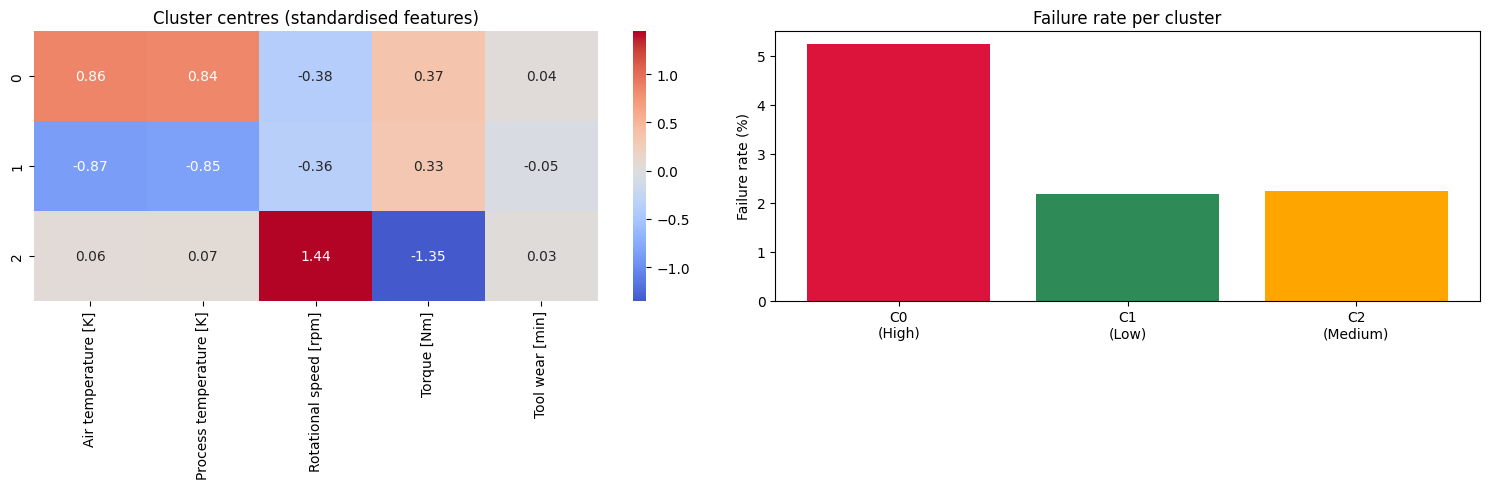

In [ ]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
centers = pd.DataFrame(km_final.cluster_centers_, columns=numeric_features)
sns.heatmap(centers, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Cluster centres (standardised features)")

colors = {"Low": "seagreen", "Medium": "orange", "High": "crimson"}
axes[1].bar([f"C{c}\n({cluster_to_risk[c]})" for c in profile.index], profile["FailureRate"],
            color=[colors[cluster_to_risk[c]] for c in profile.index])
axes[1].set_ylabel("Failure rate (%)"); axes[1].set_title("Failure rate per cluster")
plt.tight_layout(); plt.savefig("/content/cluster_risk_profile.png", dpi=120); plt.show()

## Step 8 — Conclusion (fill in after reviewing your results)
Points to address in your report:
- **SSE at k=3 and k=4** for both methods, and the observation that SSE always decreases as k increases — which is why it can't choose k alone.
- **Optimal k:** what the elbow suggested vs what the silhouette suggested. If they disagree, explain which you trust and why. AI4I is synthetic with weakly separated clusters, so silhouette scores around 0.2–0.4 are normal; don't overclaim.
- **K-Means vs Hierarchical:** K-Means is fast and scales well but needs k upfront and assumes spherical clusters. Ward hierarchical gives the full merge tree (dendrogram) and every k at once, but needs O(N²) memory. Quote your SSE and ARI values.
- **Risk tiers:** does failure rate genuinely rise from the Low to the High cluster? If the spread is large, clustering found a meaningful operating regime (e.g. high torque + low rpm + high tool wear); if it's small, say so honestly.
- **Link to dashboard:** a new sensor reading can be assigned to its nearest cluster to give a risk tier alongside the failure probability from Phase 3/4.

## Step 9 — Save artefacts for deployment

In [ ]:
import joblib, os
os.makedirs("/content/models/clustering", exist_ok=True)
joblib.dump({"scaler": scaler, "kmeans": km_final, "features": numeric_features,
             "cluster_to_risk": cluster_to_risk, "k": K_FINAL},
            "/content/models/clustering/risk_clusterer.joblib")
profile.to_csv("/content/cluster_profile.csv")
print("Saved risk clusterer.")

from google.colab import drive
drive.mount('/content/drive', force_remount=False)
!mkdir -p /content/drive/MyDrive/predictguard-ai/phase5_clustering
!cp /content/models/clustering/*.joblib /content/drive/MyDrive/predictguard-ai/phase5_clustering/
!cp /content/kmeans_k_selection.png /content/hierarchical_sse_all_k.png /content/dendrogram.png /content/cluster_scatter_pca.png /content/cluster_risk_profile.png /content/clustering_comparison.csv /content/cluster_profile.csv /content/drive/MyDrive/predictguard-ai/phase5_clustering/ 2>/dev/null
print("Copied Phase 5 outputs to Drive: MyDrive/predictguard-ai/phase5_clustering/")

Saved risk clusterer.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied Phase 5 outputs to Drive: MyDrive/predictguard-ai/phase5_clustering/
